### Base Setup

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import os
import glob
import pandas as pd
import numpy as np

# --- 1. Load Data ---
strategies = ["strategy_one", "strategy_two", "strategy_three", "strategy_four"]
dfs = []

for strategy in strategies:
    results_path = f"{strategy}_repeats/{strategy}_results/"
    csv_files = glob.glob(os.path.join(results_path, "results_*.csv"))
    
    for f in csv_files:
        df = pd.read_csv(f)
        # Ensure the 'strategy' column exists and is correctly labeled
        df['strategy'] = strategy
        
        # Handle Strategy 4 categorical context
        if strategy == "strategy_four" and 'user_preference_type' in df.columns:
            # Map 'Minimize Infection' to 0 and 'Minimize NPI' to 1
            df['user_preference_type_numeric'] = df['user_preference_type'].map({
                'Minimize Infection': 0,
                'Minimize NPI': 1
            })
        
        dfs.append(df)

if dfs:
    full_results_df = pd.concat(dfs, ignore_index=True)
    print(f"Loaded {len(full_results_df)} records across {len(dfs)} CSV files from {len(strategies)} strategies.")
    print(full_results_df.groupby('strategy').size())
else:
    print("No CSV files found.")

Loaded 12950 records across 16 CSV files from 4 strategies.
strategy
strategy_four     2880
strategy_one      1439
strategy_three    4316
strategy_two      4315
dtype: int64


In [3]:
def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    strategy_lower = str(strategy_name).lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    return None

def format_strategy_name(strategy_name):
    """Format strategy name to use words instead of digits."""
    num_to_word = {
        1: "One", 2: "Two", 3: "Three", 4: "Four", 5: "Five",
        6: "Six", 7: "Seven", 8: "Eight", 9: "Nine", 10: "Ten"
    }
    strategy_num = extract_strategy_number(strategy_name)
    if strategy_num in num_to_word:
        return f"Strategy {num_to_word[strategy_num]}"
    return str(strategy_name).replace("_", " ").title()

### Strategy One Analysis (Baseline)

In [6]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score  # AUROC uses y_true + y_score/probabilities [web:69]


def run_dce_logit_zscore_interaction_with_auroc(
    results_df,
    strategy="strategy_one",
    detailed=False,
    min_obs=10,
    plot=True,
    show_tables=True
):
    # --- Robust display/printing (Jupyter vs script) ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display  # common in notebooks [web:84]
            display(df)
        except Exception:
            # Ensure all columns show in console output [web:97]
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score (mean/std), ignoring NaNs ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()

    # --- 2. Ensure numeric ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    print(f"Prepared {len(df)} valid choice tasks.")

    per_model_rows = []

    # pooled predictions for "overall AUROC"
    pooled_y = []
    pooled_score = []
    pooled_n = 0

    # --- 6. Estimate per model ---
    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].dropna(subset=["choice", "bc_diff", "inf_diff"]).copy()
        if len(m_df) < min_obs:
            continue

        # Standardize main effects
        m_df["bc_diff_z"] = np_zscore(m_df["bc_diff"])
        m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])

        # Interaction (product of standardized variables)
        m_df["bc_x_inf_z"] = m_df["bc_diff_z"] * m_df["inf_diff_z"]

        m_df = m_df.dropna(subset=["choice", "bc_diff_z", "inf_diff_z", "bc_x_inf_z"])
        if len(m_df) < min_obs:
            continue

        if (
            m_df["bc_diff_z"].nunique(dropna=True) <= 1 or
            m_df["inf_diff_z"].nunique(dropna=True) <= 1 or
            m_df["bc_x_inf_z"].nunique(dropna=True) <= 1
        ):
            continue

        X = sm.add_constant(m_df[["bc_diff_z", "inf_diff_z", "bc_x_inf_z"]])
        y = m_df["choice"]

        try:
            res = sm.Logit(y, X).fit(disp=0)

            # Predicted probabilities (scores) for AUROC [web:69]
            y_score = np.asarray(res.predict(X), dtype=float)

            # AUROC per model (needs both classes present)
            auroc = np.nan
            if y.nunique(dropna=True) == 2:
                try:
                    auroc = float(roc_auc_score(y, y_score))
                except Exception:
                    auroc = np.nan

            # add to pooled overall AUROC
            pooled_y.append(y.to_numpy())
            pooled_score.append(y_score)
            pooled_n += int(len(m_df))

            # ORs + 95% CI
            params = res.params
            conf = res.conf_int()
            or_vals = np.exp(params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            # WTP at mean (z=0)
            wtp = np.nan
            wtp_low = np.nan
            wtp_high = np.nan

            b_bc = params.get("bc_diff_z", np.nan)
            b_inf = params.get("inf_diff_z", np.nan)

            if pd.notna(b_bc) and b_bc != 0 and pd.notna(b_inf):
                wtp = b_inf / b_bc
                cov = res.cov_params()
                if ("bc_diff_z" in cov.index) and ("inf_diff_z" in cov.index):
                    grad = np.array([-b_inf / (b_bc ** 2), 1.0 / b_bc])
                    cov2 = cov.loc[["bc_diff_z", "inf_diff_z"], ["bc_diff_z", "inf_diff_z"]].to_numpy()
                    wtp_se = float(np.sqrt(grad @ cov2 @ grad))
                    wtp_low = wtp - 1.96 * wtp_se
                    wtp_high = wtp + 1.96 * wtp_se

            per_model_rows.append({
                "Model": model_name,
                "AUROC": auroc,
                "N": int(len(m_df)),

                "OR_bc_diff_z": float(or_vals["bc_diff_z"]),
                "OR_bc_diff_z_CI_low": float(or_ci_low["bc_diff_z"]),
                "OR_bc_diff_z_CI_high": float(or_ci_high["bc_diff_z"]),

                "OR_inf_diff_z": float(or_vals["inf_diff_z"]),
                "OR_inf_diff_z_CI_low": float(or_ci_low["inf_diff_z"]),
                "OR_inf_diff_z_CI_high": float(or_ci_high["inf_diff_z"]),

                "OR_bc_x_inf_z": float(or_vals["bc_x_inf_z"]),
                "OR_bc_x_inf_z_CI_low": float(or_ci_low["bc_x_inf_z"]),
                "OR_bc_x_inf_z_CI_high": float(or_ci_high["bc_x_inf_z"]),

                "WTP_z_at_mean": float(wtp) if pd.notna(wtp) else np.nan,
                "WTP_z_at_mean_CI_low": float(wtp_low) if pd.notna(wtp_low) else np.nan,
                "WTP_z_at_mean_CI_high": float(wtp_high) if pd.notna(wtp_high) else np.nan,
            })

        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)

    # --- Overall AUROC table (separate) ---
    overall_auroc = np.nan
    if len(pooled_y) > 0:
        y_all = np.concatenate(pooled_y)
        s_all = np.concatenate(pooled_score)
        if pd.Series(y_all).nunique(dropna=True) == 2:
            try:
                overall_auroc = float(roc_auc_score(y_all, s_all))
            except Exception:
                overall_auroc = np.nan

    macro_auroc = float(per_model_df["AUROC"].mean()) if (not per_model_df.empty) else np.nan
    weighted_auroc = np.nan
    if (not per_model_df.empty) and per_model_df["AUROC"].notna().any():
        w = per_model_df["N"].where(per_model_df["AUROC"].notna(), 0).astype(float)
        if w.sum() > 0:
            weighted_auroc = float((per_model_df["AUROC"].fillna(0) * w).sum() / w.sum())

    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "Overall_AUROC_pooled": overall_auroc,     # pooled over all rows (by model) [web:69]
        "Macro_AUROC_mean_models": macro_auroc,    # mean of per-model AUROCs
        "Weighted_AUROC_by_N": weighted_auroc,     # weighted mean of per-model AUROCs by N
        "Total_N_pooled": int(pooled_n),
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0
    }])

    # Show tables
    show_df(per_model_df, "Per-model OR/WTP + AUROC")
    show_df(overall_df, "Overall AUROC summary")

    # --- 7. Plot: Forest Plot (kept; excludes OVERALL since it's in separate table) ---
    if plot and not per_model_df.empty:
        plot_df = per_model_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)

        fig, axes = plt.subplots(
            nrows=1, ncols=3,
            figsize=(18, 0.6 * len(plot_df) + 2),
            sharey=True
        )

        configs = [
            (axes[0], "OR_bc_diff_z",   "OR_bc_diff_z_CI_low",   "OR_bc_diff_z_CI_high",   "OR: bc_diff (z)"),
            (axes[1], "OR_inf_diff_z",  "OR_inf_diff_z_CI_low",  "OR_inf_diff_z_CI_high",  "OR: inf_diff (z)"),
            (axes[2], "OR_bc_x_inf_z",  "OR_bc_x_inf_z_CI_low",  "OR_bc_x_inf_z_CI_high",  "OR: bc_diff×inf_diff (z)")
        ]

        y_positions = np.arange(len(plot_df))

        for ax, x_col, low_col, high_col, title in configs:
            for idx, row in plot_df.iterrows():
                mean_val = row[x_col]
                low_val = row[low_col]
                high_val = row[high_col]

                ci_range = high_val - low_val
                is_valid_ci = pd.notna(low_val) and pd.notna(high_val) and (ci_range <= 10)
                y_pos = idx

                if is_valid_ci:
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val
                    ax.errorbar(
                        x=mean_val, y=y_pos,
                        xerr=[[left_err], [right_err]],
                        fmt="o", markersize=9, color="black",
                        capsize=5, ecolor="black"
                    )
                else:
                    ax.plot(mean_val, y_pos, "o", markersize=9, color="black")

            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=12)
            ax.set_title(title, fontsize=14, fontweight="bold")
            ax.set_xlabel("Odds Ratio")
            ax.axvline(x=1, color="red", linestyle="--", alpha=0.5)

        fig.suptitle(f"{format_strategy_name(strategy)}", fontsize=18, fontweight="bold", y=1.05)
        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        plt.show()

    return per_model_df, overall_df



### Strategy 2-4 Analysis w/ Context

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score


def run_dce_logit_zscore_context_3way_with_auroc(
    results_df,
    strategy="strategy_one",
    context_col=None,              # REQUIRED unless you pass get_context_column
    get_context_column=None,       # optional callable: get_context_column(strategy) -> column name
    detailed=False,
    min_obs=10,
    show_tables=True,
    plot=True,
    plot_ncols=3,
    plot_xlim=None                # e.g., (0, 4); None -> auto from data
):
    # --- Robust display/printing (Jupyter vs script) ---
    def show_df(df, title):
        if not show_tables:
            return
        print("\n" + "=" * 60)
        print(title)
        print("=" * 60)
        try:
            from IPython.display import display
            display(df)
        except Exception:
            print(df.to_string(index=False))

    # --- Helper: NumPy z-score (mean/std), ignoring NaNs ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- Resolve context column ---
    if context_col is None:
        if callable(get_context_column):
            context_col = get_context_column(strategy)
        if context_col is None:
            raise ValueError("context_col is required (or provide get_context_column(strategy)).")

    # --- 1. Filter strategy ---
    df = results_df[results_df["strategy"] == strategy].copy()

    # --- 2. Ensure numeric for base attributes ---
    num_cols = [
        "infection_rate_selected",
        "infection_rate_non_selected",
        "npi_level_selected",
        "npi_level_non_selected",
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # --- 3. Binary choice (Option 1 chosen?) ---
    df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)

    # --- 4. Reconstruct option attributes ---
    df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
    df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
    df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
    df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

    # --- 5. Difference coding ---
    df["bc_diff"] = df["npi_1"] - df["npi_2"]
    df["inf_diff"] = df["inf_1"] - df["inf_2"]

    # --- 6. Ensure context column is numeric (or factorize) ---
    if context_col not in df.columns:
        raise ValueError(f"context_col='{context_col}' not found in results_df.")

    ctx_numeric = pd.to_numeric(df[context_col], errors="coerce")
    if ctx_numeric.isna().all():
        codes, uniques = pd.factorize(df[context_col])
        df["_ctx"] = codes.astype(float)
        print(f"Note: context_col '{context_col}' was non-numeric; factorized into codes: {list(uniques)}")
    else:
        df["_ctx"] = ctx_numeric

    print(f"Prepared {len(df)} valid choice tasks for strategy={strategy}.")

    # Terms to include in the OR plot/table
    terms = ["inf_z", "bc_z", "ctx_z", "inf_x_bc", "inf_x_ctx", "bc_x_ctx", "inf_x_bc_x_ctx"]
    term_labels = {
        "inf_z": "OR: inf_diff (z)",
        "bc_z": "OR: bc_diff (z)",
        "ctx_z": f"OR: {context_col} (z)",
        "inf_x_bc": "OR: inf×bc",
        "inf_x_ctx": "OR: inf×ctx",
        "bc_x_ctx": "OR: bc×ctx",
        "inf_x_bc_x_ctx": "OR: inf×bc×ctx",
    }

    per_model_rows = []
    pooled_y, pooled_score, pooled_n = [], [], 0

    # --- 7. Estimate per model ---
    for model_name in df["model"].dropna().unique():
        m_df = df[df["model"] == model_name].dropna(subset=["choice", "bc_diff", "inf_diff", "_ctx"]).copy()
        if len(m_df) < min_obs:
            continue

        # z-score within model
        m_df["inf_z"] = np_zscore(m_df["inf_diff"])
        m_df["bc_z"] = np_zscore(m_df["bc_diff"])
        m_df["ctx_z"] = np_zscore(m_df["_ctx"])

        m_df = m_df.dropna(subset=["choice", "inf_z", "bc_z", "ctx_z"])
        if len(m_df) < min_obs:
            continue

        if (
            m_df["inf_z"].nunique(dropna=True) <= 1 or
            m_df["bc_z"].nunique(dropna=True) <= 1 or
            m_df["ctx_z"].nunique(dropna=True) <= 1
        ):
            continue

        # Build requested interaction set
        m_df["inf_x_bc"] = m_df["inf_z"] * m_df["bc_z"]
        m_df["inf_x_ctx"] = m_df["inf_z"] * m_df["ctx_z"]
        m_df["bc_x_ctx"] = m_df["bc_z"] * m_df["ctx_z"]
        m_df["inf_x_bc_x_ctx"] = m_df["inf_z"] * m_df["bc_z"] * m_df["ctx_z"]

        needed = ["choice"] + terms
        m_df = m_df.dropna(subset=needed)
        if len(m_df) < min_obs:
            continue

        X = sm.add_constant(m_df[terms])
        y = m_df["choice"]

        if y.nunique(dropna=True) < 2:
            continue

        try:
            res = sm.Logit(y, X).fit(disp=0)

            # AUROC per model from predicted probabilities [web:69]
            y_score = np.asarray(res.predict(X), dtype=float)
            auroc = float(roc_auc_score(y, y_score))

            pooled_y.append(y.to_numpy())
            pooled_score.append(y_score)
            pooled_n += int(len(m_df))

            # ORs + 95% CI
            conf = res.conf_int()
            or_vals = np.exp(res.params)
            or_ci_low = np.exp(conf[0])
            or_ci_high = np.exp(conf[1])

            row = {"Model": model_name, "AUROC": auroc, "N": int(len(m_df)), "context_col": context_col}
            for t in terms:
                row[f"OR_{t}"] = float(or_vals[t]) if t in or_vals.index else np.nan
                row[f"OR_{t}_CI_low"] = float(or_ci_low[t]) if t in or_ci_low.index else np.nan
                row[f"OR_{t}_CI_high"] = float(or_ci_high[t]) if t in or_ci_high.index else np.nan

            per_model_rows.append(row)

        except Exception as e:
            print(f"Skipping model {model_name} due to error: {e}")
            continue

    per_model_df = pd.DataFrame(per_model_rows).sort_values("Model").reset_index(drop=True)

    # --- Overall AUROC summary (separate table) ---
    overall_auroc = np.nan
    if len(pooled_y) > 0:
        y_all = np.concatenate(pooled_y)
        s_all = np.concatenate(pooled_score)
        if pd.Series(y_all).nunique(dropna=True) == 2:
            overall_auroc = float(roc_auc_score(y_all, s_all))

    macro_auroc = float(per_model_df["AUROC"].mean()) if not per_model_df.empty else np.nan
    weighted_auroc = np.nan
    if not per_model_df.empty and per_model_df["AUROC"].notna().any():
        w = per_model_df["N"].where(per_model_df["AUROC"].notna(), 0).astype(float)
        if w.sum() > 0:
            weighted_auroc = float((per_model_df["AUROC"].fillna(0) * w).sum() / w.sum())

    overall_df = pd.DataFrame([{
        "Strategy": strategy,
        "context_col": context_col,
        "Overall_AUROC_pooled": overall_auroc,
        "Macro_AUROC_mean_models": macro_auroc,
        "Weighted_AUROC_by_N": weighted_auroc,
        "Total_N_pooled": int(pooled_n),
        "Models_included": int(per_model_df["Model"].nunique()) if not per_model_df.empty else 0
    }])

    show_df(per_model_df, "Per-model ORs (3-way interaction set) + AUROC")
    show_df(overall_df, "Overall AUROC summary")

    # --- 8. Visualization: OR forest plots for each term ---
    if plot and (not per_model_df.empty):
        plot_df = per_model_df.copy()
        plot_df["Model"] = plot_df["Model"].astype(str)

        n_terms = len(terms)
        ncols = int(plot_ncols)
        nrows = int(np.ceil(n_terms / ncols))

        fig, axes = plt.subplots(
            nrows=nrows,
            ncols=ncols,
            figsize=(6.0 * ncols, 0.55 * len(plot_df) * nrows + 2.5),
            sharey=True
        )
        axes = np.array(axes).reshape(-1)

        y_positions = np.arange(len(plot_df))

        # Determine x-limits
        if plot_xlim is None:
            vals = []
            for t in terms:
                vals.append(plot_df[f"OR_{t}"].to_numpy())
                vals.append(plot_df[f"OR_{t}_CI_low"].to_numpy())
                vals.append(plot_df[f"OR_{t}_CI_high"].to_numpy())
            vals = np.concatenate([v[np.isfinite(v)] for v in vals if v is not None])
            if vals.size > 0:
                xmin = max(0, float(np.nanmin(vals)) * 0.90)
                xmax = float(np.nanmax(vals)) * 1.10
                plot_xlim_use = (xmin, xmax)
            else:
                plot_xlim_use = (0, 4)
        else:
            plot_xlim_use = plot_xlim

        for i, t in enumerate(terms):
            ax = axes[i]
            x_col = f"OR_{t}"
            lo_col = f"OR_{t}_CI_low"
            hi_col = f"OR_{t}_CI_high"

            for idx, row in plot_df.iterrows():
                mean_val = row[x_col]
                low_val = row[lo_col]
                high_val = row[hi_col]

                if pd.notna(mean_val) and pd.notna(low_val) and pd.notna(high_val):
                    left_err = mean_val - low_val
                    right_err = high_val - mean_val

                    ax.errorbar(
                        x=mean_val,
                        y=idx,
                        xerr=[[left_err], [right_err]],
                        fmt="o",
                        markersize=7,
                        color="black",
                        ecolor="black",
                        capsize=4
                    )
                elif pd.notna(mean_val):
                    ax.plot(mean_val, idx, "o", markersize=7, color="black")

            ax.set_title(term_labels.get(t, t), fontsize=13, fontweight="bold")
            ax.axvline(x=1, color="red", linestyle="--", alpha=0.5)
            ax.set_xlim(*plot_xlim_use)
            ax.grid(True, axis="x", alpha=0.25)
            ax.set_xlabel("Odds Ratio")

            ax.set_yticks(y_positions)
            ax.set_yticklabels(plot_df["Model"], fontsize=11)

        # Hide any unused axes
        for j in range(n_terms, len(axes)):
            axes[j].set_visible(False)

        fig.suptitle(f"{strategy}: ORs by model (with 95% CI)", fontsize=16, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()

    return per_model_df, overall_df


### Strategy 1

Prepared 1439 valid choice tasks.

Per-model OR/WTP + AUROC


,Model,AUROC,N,OR_bc_diff_z,OR_bc_diff_z_CI_low,OR_bc_diff_z_CI_high,OR_inf_diff_z,OR_inf_diff_z_CI_low,OR_inf_diff_z_CI_high,OR_bc_x_inf_z,OR_bc_x_inf_z_CI_low,OR_bc_x_inf_z_CI_high,WTP_z_at_mean,WTP_z_at_mean_CI_low,WTP_z_at_mean_CI_high
0,deepseek/deepseek-chat-v3.1,0.772297,360,2.171050,1.691401,2.786720,0.435766,0.338588,0.560835,1.055927,0.801215,1.391614,-1.071514,-1.493833,-0.649195
1,google/gemini-2.5-flash,0.941798,359,1.381248,1.011432,1.886281,0.022218,0.008417,0.058647,9.194806,4.157507,20.335376,-11.786349,-23.569127,-0.003570
2,openai/gpt-5-nano,0.971972,360,0.152446,0.089097,0.260837,0.010923,0.004093,0.029148,1.931485,0.926691,4.025759,2.401394,1.882667,2.920121
3,x-ai/grok-4-fast,0.984344,360,0.104670,0.051552,0.212519,0.001921,0.000418,0.008841,1.653739,0.631534,4.330488,2.771309,2.161875,3.380743



Overall AUROC summary


,Strategy,Overall_AUROC_pooled,Macro_AUROC_mean_models,Weighted_AUROC_by_N,Total_N_pooled,Models_included
0,strategy_one,0.9501,0.917603,0.917586,1439,4


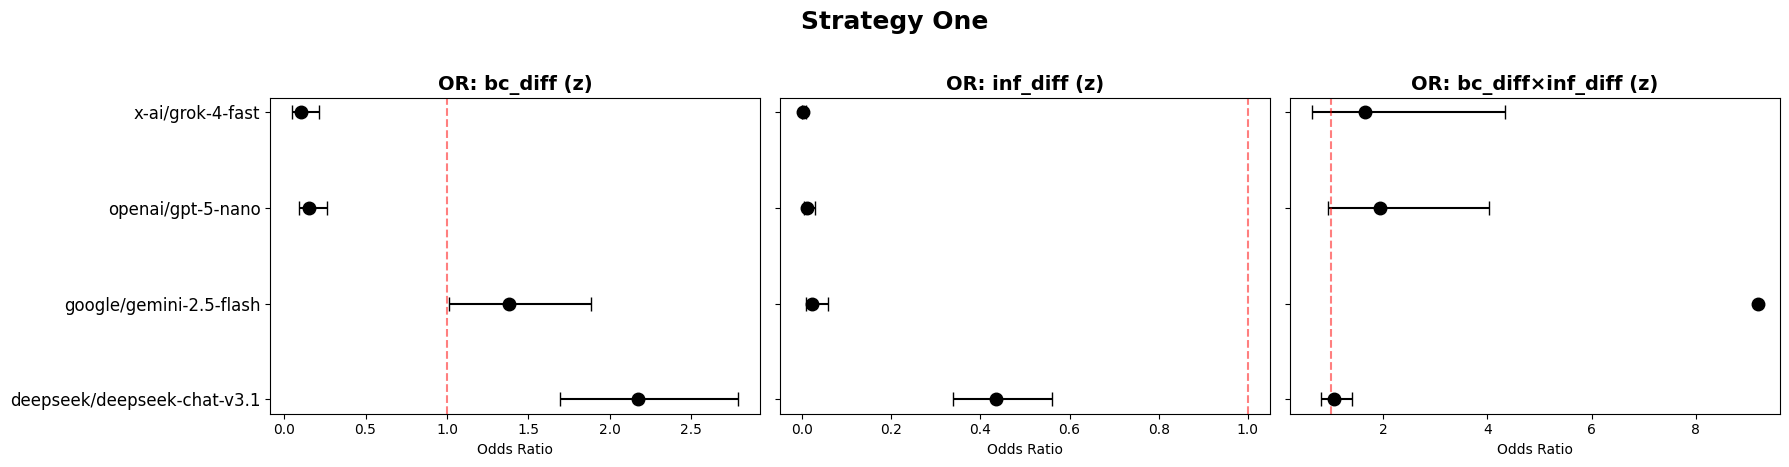

(                         Model     AUROC    N  OR_bc_diff_z  \
 0  deepseek/deepseek-chat-v3.1  0.772297  360      2.171050   
 1      google/gemini-2.5-flash  0.941798  359      1.381248   
 2            openai/gpt-5-nano  0.971972  360      0.152446   
 3             x-ai/grok-4-fast  0.984344  360      0.104670   
 
    OR_bc_diff_z_CI_low  OR_bc_diff_z_CI_high  OR_inf_diff_z  \
 0             1.691401              2.786720       0.435766   
 1             1.011432              1.886281       0.022218   
 2             0.089097              0.260837       0.010923   
 3             0.051552              0.212519       0.001921   
 
    OR_inf_diff_z_CI_low  OR_inf_diff_z_CI_high  OR_bc_x_inf_z  \
 0              0.338588               0.560835       1.055927   
 1              0.008417               0.058647       9.194806   
 2              0.004093               0.029148       1.931485   
 3              0.000418               0.008841       1.653739   
 
    OR_bc_x_inf_z_CI_low

In [12]:
run_dce_logit_zscore_interaction_with_auroc(full_results_df, strategy="strategy_one")

### Strategy Two Analysis (Political Orientation)

In [15]:
run_dce_logit_zscore_context_3way_with_auroc(full_results_df, strategy="strategy_two", context_col="capacity_context")

Prepared 4315 valid choice tasks for strategy=strategy_two.

Per-model ORs (requested 3-way interaction set) + AUROC


,Model,AUROC,N,context_col,OR_inf_z,OR_inf_z_CI_low,OR_inf_z_CI_high,OR_bc_z,OR_bc_z_CI_low,OR_bc_z_CI_high,...,OR_inf_x_bc_CI_high,OR_inf_x_ctx,OR_inf_x_ctx_CI_low,OR_inf_x_ctx_CI_high,OR_bc_x_ctx,OR_bc_x_ctx_CI_low,OR_bc_x_ctx_CI_high,OR_inf_x_bc_x_ctx,OR_inf_x_bc_x_ctx_CI_low,OR_inf_x_bc_x_ctx_CI_high
0,deepseek/deepseek-chat-v3.1,0.728218,1080,capacity_context,0.503121,0.437270,0.578889,1.790996,1.560062,2.056114,...,1.166737,1.088185,0.945738,1.252089,1.000973,0.871910,1.149141,1.025558,0.881173,1.193601
1,google/gemini-2.5-flash,0.932919,1075,capacity_context,0.057909,0.040022,0.083791,1.610165,1.323371,1.959111,...,4.906820,0.946409,0.654627,1.368243,1.013242,0.832553,1.233146,1.105804,0.781925,1.563834
2,openai/gpt-5-nano,0.979524,1080,capacity_context,0.004105,0.001882,0.008953,0.105530,0.070740,0.157429,...,2.440663,2.719789,1.288045,5.743005,1.710806,1.162700,2.517292,1.355050,0.837538,2.192331
3,x-ai/grok-4-fast,0.990708,1080,capacity_context,0.000321,0.000083,0.001239,0.079882,0.048958,0.130341,...,5.248657,0.586219,0.154329,2.226761,0.879195,0.540485,1.430167,1.399018,0.625531,3.128947



Overall AUROC summary


,Strategy,context_col,Overall_AUROC_pooled,Macro_AUROC_mean_models,Weighted_AUROC_by_N,Total_N_pooled,Models_included
0,strategy_two,capacity_context,0.9521,0.907842,0.907813,4315,4


(                         Model     AUROC     N       context_col  OR_inf_z  \
 0  deepseek/deepseek-chat-v3.1  0.728218  1080  capacity_context  0.503121   
 1      google/gemini-2.5-flash  0.932919  1075  capacity_context  0.057909   
 2            openai/gpt-5-nano  0.979524  1080  capacity_context  0.004105   
 3             x-ai/grok-4-fast  0.990708  1080  capacity_context  0.000321   
 
    OR_inf_z_CI_low  OR_inf_z_CI_high   OR_bc_z  OR_bc_z_CI_low  \
 0         0.437270          0.578889  1.790996        1.560062   
 1         0.040022          0.083791  1.610165        1.323371   
 2         0.001882          0.008953  0.105530        0.070740   
 3         0.000083          0.001239  0.079882        0.048958   
 
    OR_bc_z_CI_high  ...  OR_inf_x_bc_CI_high  OR_inf_x_ctx  \
 0         2.056114  ...             1.166737      1.088185   
 1         1.959111  ...             4.906820      0.946409   
 2         0.157429  ...             2.440663      2.719789   
 3         0.1

### Strategy Three Analysis (Economic Context)

Prepared 4316 valid choice tasks.

OR + WTP (WITH CI) — STRATEGY: STRATEGY_THREE (INTERACTIONS)


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_economic_context,OR_economic_context_CI_low,OR_economic_context_CI_high,OR_cost_x_economic_context,OR_cost_x_economic_context_CI_low,OR_cost_x_economic_context_CI_high,OR_inf_x_economic_context,OR_inf_x_economic_context_CI_low,OR_inf_x_economic_context_CI_high,WTP,WTP_CI_low,WTP_CI_high
0,deepseek/deepseek-chat-v3.1,1080,1.508750,1.187642,1.916677,0.952955,0.929272,0.977241,0.995416,0.987043,1.003861,1.002232,0.995241,1.009273,1.000079,0.999348,1.000810,-0.117166,-0.203806,-0.030525
1,google/gemini-2.5-flash,1076,1.329222,0.957770,1.844735,0.757272,0.706289,0.811935,0.995342,0.981492,1.009386,1.000949,0.991368,1.010622,0.999732,0.997665,1.001803,-0.976947,-2.080123,0.126230
2,openai/gpt-5-nano,1080,0.115461,0.054052,0.246637,0.545839,0.459640,0.648205,0.991456,0.971957,1.011346,1.005399,0.984339,1.026909,1.001907,0.997192,1.006645,0.280445,0.215692,0.345197
3,x-ai/grok-4-fast,1080,0.411757,0.261767,0.647690,0.729575,0.658525,0.808291,1.006007,0.988966,1.023341,0.983797,0.968593,0.999239,0.995154,0.991407,0.998916,0.355331,0.197513,0.513149


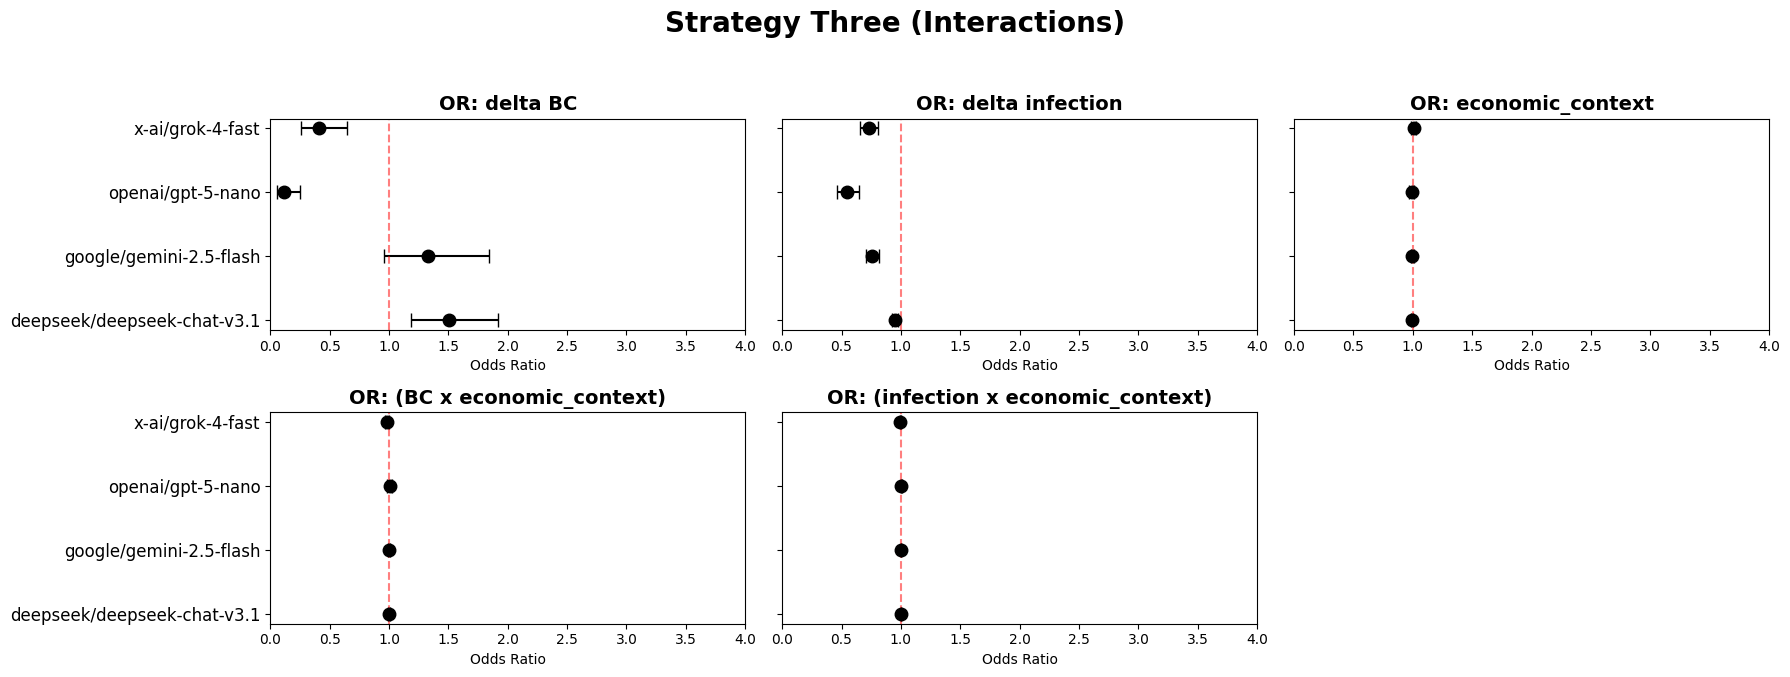

In [ ]:
if 'full_results_df' in locals():
    analysis_results_three = run_dce_logit_interactions_custom(full_results_df, strategy="strategy_three", context_col="economic_context")

Prepared 4316 valid choice tasks for strategy_three (Main Effects Only).


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_economic_context,OR_economic_context_CI_low,OR_economic_context_CI_high
0,deepseek/deepseek-chat-v3.1,1080,1.613922,1.439711,1.809213,0.955247,0.943926,0.966703,0.995109,0.986973,1.003312
1,google/gemini-2.5-flash,1076,1.367596,1.168810,1.600190,0.751252,0.726285,0.777077,0.994427,0.982291,1.006712
2,openai/gpt-5-nano,1080,0.136763,0.096939,0.192949,0.579463,0.536770,0.625551,0.991980,0.972608,1.011739
3,x-ai/grok-4-fast,1080,0.267540,0.209883,0.341037,0.642813,0.606662,0.681118,1.002783,0.986528,1.019305


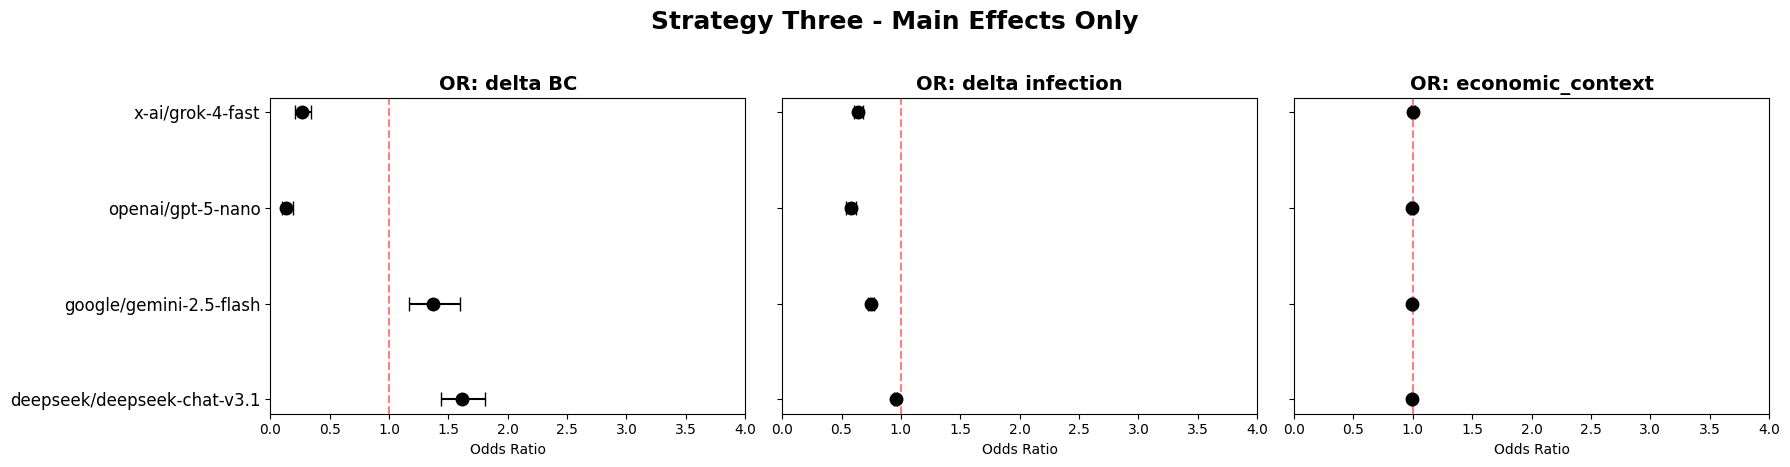

In [ ]:
if 'full_results_df' in locals():
    analysis_results_three_main = run_dce_logit_with_context(full_results_df, strategy="strategy_three", context_col="economic_context")

### Strategy Four Analysis (User Preference)

Prepared 2880 valid choice tasks.

OR + WTP (WITH CI) — STRATEGY: STRATEGY_FOUR (INTERACTIONS)


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_user_preference_type_numeric,OR_user_preference_type_numeric_CI_low,OR_user_preference_type_numeric_CI_high,OR_cost_x_user_preference_type_numeric,OR_cost_x_user_preference_type_numeric_CI_low,OR_cost_x_user_preference_type_numeric_CI_high,OR_inf_x_user_preference_type_numeric,OR_inf_x_user_preference_type_numeric_CI_low,OR_inf_x_user_preference_type_numeric_CI_high,WTP,WTP_CI_low,WTP_CI_high
0,deepseek/deepseek-chat-v3.1,720,2.071461,1.583361,2.710026,0.795688,0.760742,0.832240,1.044898,0.694437,1.572227,0.154421,0.107131,0.222585,1.250538,1.190124,1.314019,-0.313829,-0.422652,-0.205006
1,google/gemini-2.5-flash,720,2.651531,1.823728,3.855080,0.693092,0.636041,0.755260,0.343930,0.178983,0.660888,0.279910,0.182211,0.429992,1.275629,1.165595,1.396050,-0.375939,-0.492088,-0.259790
2,openai/gpt-5-nano,720,0.070996,0.029534,0.170663,0.481439,0.391636,0.591833,1.022079,0.413404,2.526937,2.116174,0.759247,5.898205,1.318161,1.045299,1.662251,0.276348,0.225433,0.327263
3,x-ai/grok-4-fast,720,0.122654,0.061800,0.243431,0.491953,0.404152,0.598827,1.114359,0.343595,3.614124,0.504034,0.149880,1.695023,0.804620,0.562376,1.151212,0.338056,0.249381,0.426732


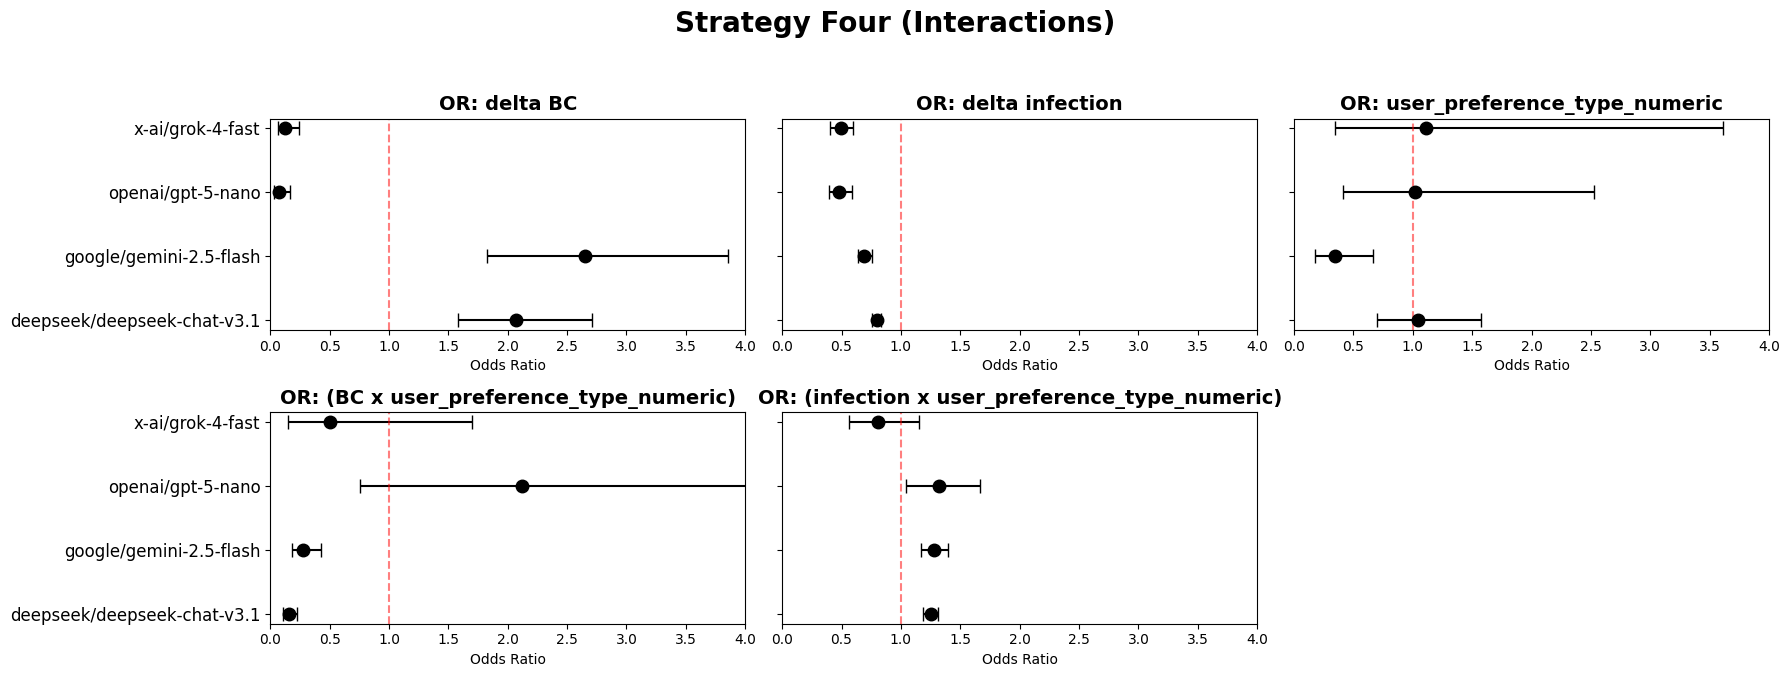

In [ ]:
if 'full_results_df' in locals():
    analysis_results_four = run_dce_logit_interactions_custom(full_results_df, strategy="strategy_four", context_col="user_preference_type_numeric")

Prepared 2880 valid choice tasks for strategy_four (Main Effects Only).


,Model,N,OR_cost_diff,OR_cost_diff_CI_low,OR_cost_diff_CI_high,OR_inf_diff,OR_inf_diff_CI_low,OR_inf_diff_CI_high,OR_user_preference_type_numeric,OR_user_preference_type_numeric_CI_low,OR_user_preference_type_numeric_CI_high
0,deepseek/deepseek-chat-v3.1,720,0.739221,0.648080,0.843179,0.932260,0.918552,0.946172,1.141899,0.829641,1.571684
1,google/gemini-2.5-flash,720,1.089822,0.928957,1.278542,0.839500,0.818641,0.860890,1.064911,0.712844,1.590859
2,openai/gpt-5-nano,720,0.117708,0.075188,0.184275,0.577152,0.523854,0.635872,1.377956,0.626246,3.031977
3,x-ai/grok-4-fast,720,0.093179,0.052937,0.164013,0.451326,0.382539,0.532482,1.000000,0.333813,2.995692


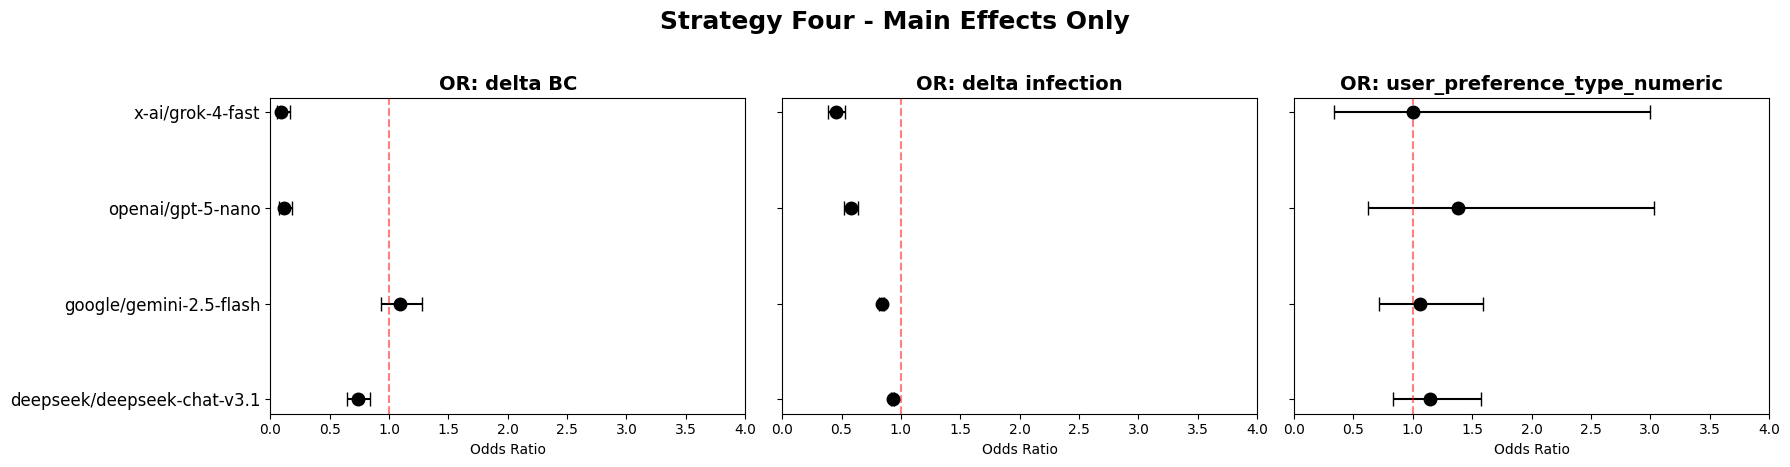

In [ ]:
if 'full_results_df' in locals():
    analysis_results_four_main = run_dce_logit_with_context(full_results_df, strategy="strategy_four", context_col="user_preference_type_numeric")

### Scatterplot

In [ ]:
import re
import string
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns


def plot_or_inf_vs_bc_4panel(
    results_df,
    strategies=None,                 # None -> auto from results_df, sorted by strategy number
    min_obs=10,
    FIG_SIZE_MULTI=(14, 10),
    wspace=0.15,
    point_size=250,
    alpha=0.9,
    pad_frac=0.10,
    title_fontsize=15               # reduced title font size
):
    # --- Extract strategy number robustly (digits OR words one-four) ---
    def extract_strategy_number(s):
        s = str(s)
        m = re.search(r"(\d+)", s)
        if m:
            return int(m.group(1))
        word_map = {
            "one": 1, "two": 2, "three": 3, "four": 4,
            "1": 1, "2": 2, "3": 3, "4": 4
        }
        s_low = s.lower()
        for k, v in word_map.items():
            if k in s_low:
                return v
        return 9999

    # --- Standardize model names to requested display labels ---
    def standardize_model_name(raw):
        s = str(raw).strip()
        s_low = s.lower()

        if "deepseek" in s_low:
            return "DeepSeek"
        if "gemini" in s_low:
            return "Gemini"
        if "grok" in s_low:
            return "Grok"
        if "gpt" in s_low or "chatgpt" in s_low or "openai" in s_low:
            return "ChatGPT"

        # If it doesn't match, keep original (so you can see what's unmapped)
        return s

    # --- Helper: NumPy z-score (mean/std), ignoring NaNs ---
    def np_zscore(series: pd.Series) -> pd.Series:
        arr = np.asarray(series, dtype=float)
        mu = np.nanmean(arr)
        sigma = np.nanstd(arr, ddof=0)
        if (not np.isfinite(sigma)) or sigma == 0:
            return pd.Series(np.full_like(arr, np.nan, dtype=float), index=series.index)
        return pd.Series((arr - mu) / sigma, index=series.index)

    # --- Fit ORs for one strategy ---
    def fit_strategy_or_df(df_strategy: pd.DataFrame, strategy_value):
        df = df_strategy.copy()

        # Ensure numeric
        num_cols = [
            "infection_rate_selected",
            "infection_rate_non_selected",
            "npi_level_selected",
            "npi_level_non_selected",
        ]
        for c in num_cols:
            df[c] = pd.to_numeric(df[c], errors="coerce")

        # Binary choice (Option 1 chosen?)
        df["choice"] = (df["selected_choice"] == df["pair"].str.split("-").str[0]).astype(int)

        # Reconstruct option attributes
        df["inf_1"] = np.where(df["choice"] == 1, df["infection_rate_selected"], df["infection_rate_non_selected"])
        df["inf_2"] = np.where(df["choice"] == 1, df["infection_rate_non_selected"], df["infection_rate_selected"])
        df["npi_1"] = np.where(df["choice"] == 1, df["npi_level_selected"], df["npi_level_non_selected"])
        df["npi_2"] = np.where(df["choice"] == 1, df["npi_level_non_selected"], df["npi_level_selected"])

        # Diffs
        df["bc_diff"] = df["npi_1"] - df["npi_2"]
        df["inf_diff"] = df["inf_1"] - df["inf_2"]

        rows = []
        for raw_model in df["model"].dropna().unique():
            m_df = df[df["model"] == raw_model].dropna(subset=["choice", "bc_diff", "inf_diff"]).copy()
            if len(m_df) < min_obs:
                continue

            # z-score within model (as in your logit function)
            m_df["bc_diff_z"] = np_zscore(m_df["bc_diff"])
            m_df["inf_diff_z"] = np_zscore(m_df["inf_diff"])
            m_df = m_df.dropna(subset=["choice", "bc_diff_z", "inf_diff_z"])
            if len(m_df) < min_obs:
                continue

            if m_df["bc_diff_z"].nunique(dropna=True) <= 1 or m_df["inf_diff_z"].nunique(dropna=True) <= 1:
                continue

            X = sm.add_constant(m_df[["bc_diff_z", "inf_diff_z"]])
            y = m_df["choice"]

            try:
                res = sm.Logit(y, X).fit(disp=0)
                or_vals = np.exp(res.params)

                rows.append({
                    "strategy": strategy_value,
                    "Model": standardize_model_name(raw_model),
                    "OR_inf_diff_z": float(or_vals["inf_diff_z"]),
                    "OR_bc_diff_z": float(or_vals["bc_diff_z"]),
                    "N": int(len(m_df))
                })
            except Exception:
                continue

        return pd.DataFrame(rows)

    # --- Choose strategies (default: all, sorted), then take first 4 ---
    if strategies is None:
        strategies_sorted = sorted(results_df["strategy"].dropna().unique(), key=extract_strategy_number)
    else:
        strategies_sorted = list(strategies)
    strategies_sorted = strategies_sorted[:4]

    # --- Fit all strategies ---
    all_rows = []
    for strat in strategies_sorted:
        s_df = results_df[results_df["strategy"] == strat]
        all_rows.append(fit_strategy_or_df(s_df, strat))
    or_df = pd.concat(all_rows, ignore_index=True) if len(all_rows) else pd.DataFrame()

    # --- Build model colors with requested palette code ---
    unique_models = sorted(or_df["Model"].unique()) if not or_df.empty else []
    _palette_raw = sns.color_palette("tab10", n_colors=len(unique_models))
    MODEL_COLORS = dict(zip(unique_models, _palette_raw))  # model -> color

    # --- Create 2x2 panels (always) ---
    fig, axes = plt.subplots(
        2, 2,
        figsize=FIG_SIZE_MULTI,
        sharex=True,
        sharey=True,
        gridspec_kw={"wspace": wspace}
    )
    axes_flat = np.array(axes).flatten()

    if or_df.empty:
        for i, ax in enumerate(axes_flat):
            ax.set_visible(False)
        plt.show()
        return or_df

    # --- SYMMETRIC global limits (identical x/y limits) ---
    vmin = float(np.nanmin([or_df["OR_inf_diff_z"].min(), or_df["OR_bc_diff_z"].min()]))
    vmax = float(np.nanmax([or_df["OR_inf_diff_z"].max(), or_df["OR_bc_diff_z"].max()]))

    span = vmax - vmin
    pad = span * pad_frac if np.isfinite(span) and span > 0 else 0.5
    lims = (vmin - pad, vmax + pad)

    # --- Model legend handles (top center) ---
    model_handles = [
        plt.Line2D(
            [0], [0], marker="o", color="w",
            markerfacecolor=MODEL_COLORS[m],
            markersize=12, markeredgecolor="black",
            label=m
        )
        for m in unique_models
    ]

    # --- Plot each strategy panel ---
    for idx in range(4):
        ax = axes_flat[idx]

        if idx >= len(strategies_sorted):
            ax.set_visible(False)
            continue

        strat = strategies_sorted[idx]
        d = or_df[or_df["strategy"] == strat].copy()

        strat_num = extract_strategy_number(strat)
        ax.set_title(
            f"{string.ascii_uppercase[idx]}) Prompting Strategy {strat_num}",
            fontsize=title_fontsize,
            fontweight="bold",
            loc="left",
            pad=12
        )

        ax.set_xlim(*lims)
        ax.set_ylim(*lims)
        ax.grid(True, alpha=0.3)
        ax.set_box_aspect(1)
        ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)

        # Dashed y=x line
        ax.plot([lims[0], lims[1]], [lims[0], lims[1]], linestyle="--", color="gray", linewidth=2)

        if d.empty:
            continue

        for _, row in d.iterrows():
            ax.scatter(
                row["OR_inf_diff_z"], row["OR_bc_diff_z"],
                s=point_size,
                c=[MODEL_COLORS[row["Model"]]],
                marker="o",
                edgecolor="black",
                linewidth=1.5,
                alpha=alpha
            )

    # Axis labels
    for ax in axes[:, 0]:
        ax.set_ylabel("OR bc_diff (z)", fontsize=18)
    for ax in axes[-1, :]:
        if ax.get_visible():
            ax.set_xlabel("OR inf_diff (z)", fontsize=18)

    # Top-center model legend
    fig.legend(
        handles=model_handles,
        title="Model",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.01),
        ncol=max(1, len(unique_models)),
        fontsize=16,
        title_fontsize=18,
        frameon=True,
        borderaxespad=0
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    return or_df


/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_63393/3816405429.py:242: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


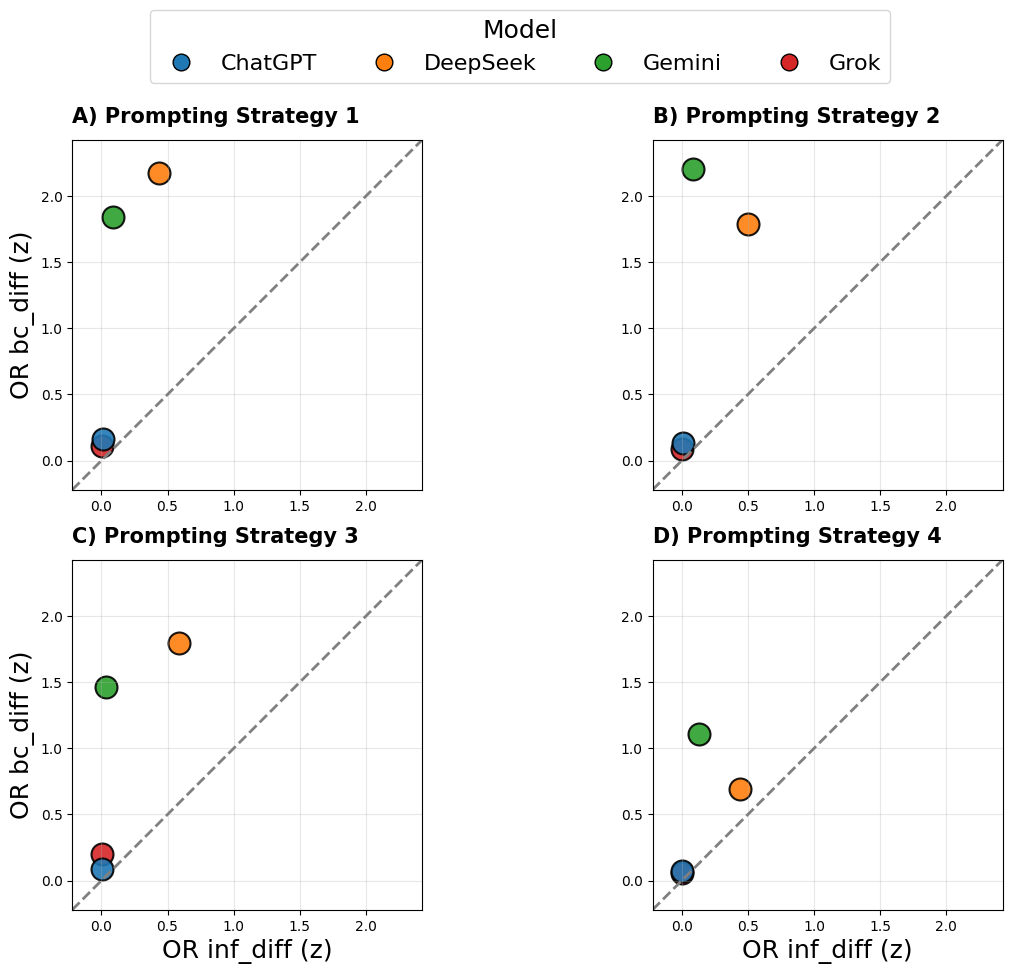

,strategy,Model,OR_inf_diff_z,OR_bc_diff_z,N
0,strategy_one,DeepSeek,0.435451,2.173010,360
1,strategy_one,Grok,0.002085,0.111219,360
2,strategy_one,ChatGPT,0.012440,0.160106,360
3,strategy_one,Gemini,0.086504,1.841969,359
4,strategy_two,DeepSeek,0.503906,1.789716,1080
5,strategy_two,Grok,0.000443,0.084705,1080
6,strategy_two,ChatGPT,0.006250,0.131051,1080
7,strategy_two,Gemini,0.085182,2.205935,1075
8,strategy_three,DeepSeek,0.587283,1.795807,1080
9,strategy_three,Grok,0.005845,0.199039,1080


In [ ]:
plot_or_inf_vs_bc_4panel(results_df=full_results_df)